In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# Debug
import ipdb
deb = ipdb.set_trace

import os
os.environ["KERAS_BACKEND"] = "torch"                                               
from importlib.util import find_spec
import sys


import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import datetime
import sys
from keras import ops
import nibabel as nb
import keras
import torch

torch._dynamo.config.automatic_dynamic_shapes = False
from prfmodel.stimuli import PRFStimulus
from prfmodel.impulse import DerivativeTwoGammaImpulse
from prfmodel.models.prf import Gaussian2DPRFModel
from prfmodel.fitters import GridFitter
from prfmodel.fitters import LeastSquaresFitter
from prfmodel.models.prf import init_css_from_gaussian
from prfmodel.fitters import SGDFitter
from prfmodel.fitters.adapter import Adapter, ParameterTransform
from prfmodel.utils import batched
from prfmodel.models.compression import CompressiveEncoder
from prfmodel.models.prf import PRFStimulusEncoder
from prfmodel.fitters.losses import CorrelationLoss

# Personal imports
sys.path.append("{}/../../analysis_code/utils".format(os.getcwd()))
from maths_utils import r2_score_surf
from settings_utils import load_settings
from screen_utils import get_screen_settings
from pycortex_utils import set_pycortex_config_file
from surface_utils import load_surface ,make_surface_image
from prfmodel.models.prf.canonical import CanonicalPRFModel
from prfmodel_utils import PolarGaussian2DPRFTuning, polar_to_cartesian, bounded_transform, clip_to_bounds, host_safe

In [2]:
# Inputs
main_dir = '/Users/uriel/disks/meso_shared'
project_dir = 'RetinoMaps'
subject = 'sub-01'
format_ = '170k'
analysis_name = 'prf'
task_name = 'pRF'
input_fn = '{}/{}/derivatives/pp_data/{}/{}/func/fmriprep_dct_z-score_avg/{}_task-pRF_fmriprep_dct_z-score_avg_bold.dtseries.nii'.format(main_dir, project_dir, subject, format_, subject) 
n_jobs = 20
sub_num = subject[4:]

In [3]:
n_batches = n_jobs
verbose = True
css_params_num = 9

# Load settings
base_dir = os.path.abspath(os.path.join(os.getcwd(), "../../"))
general_settings_path = os.path.join(base_dir, project_dir, "settings.yml")
analysis_settings_path = os.path.join(base_dir, project_dir, f"{analysis_name}-analysis.yml")
settings = load_settings([general_settings_path, analysis_settings_path])
analysis_info = settings[0]

tr = analysis_info['TR']
gauss_grid_nr = analysis_info['gauss_grid_nr']
max_ecc_size = analysis_info['max_ecc_size']
css_grid_nr = analysis_info['css_grid_nr']
css_exponent_bounds = analysis_info['n_th']

# # Load screen settings from subject dependent task-events.json
# task_name = input_fn.split("task-")[1].split("_")[0]  # from the file path
# screen_size_cm, screen_distance_cm = get_screen_settings(main_dir, project_dir, sub_num, task_name)

screen_size_cm = [77.33, 43.5]
screen_distance_cm = 120

In [4]:
# Override with fake screen settings if defined in analysis yml
if 'fake_screen_size_cm' in analysis_info:
    print("[INFO] Fake screen size found in settings — overriding real screen size.")
    screen_size_cm = analysis_info['fake_screen_size_cm']

print(f"Fitting data: {input_fn}\n")
print("\n===== PRF FIT PARAMETERS =====")
print(f"fit : {input_fn}")
print(f"Screen Size (cm): {screen_size_cm} {'[FAKE]' if 'fake_screen_size_cm' in analysis_info else '[REAL]'}")
print(f"Screen Distance (cm): {screen_distance_cm}")
print(f"TR: {tr}")
print(f"Max eccentricity/size values: {max_ecc_size}") 
print(f"Inputing x/y = [-{max_ecc_size * 0.5}, {max_ecc_size * 0.5}]")
print("==============================\n")
# Set pycortex db and colormaps
cortex_dir = "{}/{}/derivatives/pp_data/cortex".format(main_dir, project_dir)
set_pycortex_config_file(cortex_dir)

# Get task specific (visual) design matrix
# Find dm: check subject-specific directory first, then general vdm directory
dm_name = analysis_info['dm_name']
dm_name_tofind = dm_name[1:] if dm_name else "vdm"
dm_base_dir = '{}/{}/derivatives/vdm'.format(main_dir, project_dir)
dm_fn_subject = '{}/sub-{}/sub-{}_task-{}_{}.npy'.format(dm_base_dir, sub_num, sub_num, task_name, dm_name_tofind)
dm_fn_general = '{}/task-{}_{}.npy'.format(dm_base_dir, task_name, dm_name_tofind)


if os.path.isfile(dm_fn_subject):
    dm_fn = dm_fn_subject
elif os.path.isfile(dm_fn_general):
    dm_fn = dm_fn_general
else:
    raise FileNotFoundError(
        f"No DM found for task '{task_name}'.\n"
        f"  Checked: {dm_fn_subject}\n"
        f"  Checked: {dm_fn_general}"
    )

print(f"Loading DM from: {dm_fn}")
dm = np.load(dm_fn)

Fitting data: /Users/uriel/disks/meso_shared/RetinoMaps/derivatives/pp_data/sub-01/170k/func/fmriprep_dct_z-score_avg/sub-01_task-pRF_fmriprep_dct_z-score_avg_bold.dtseries.nii


===== PRF FIT PARAMETERS =====
fit : /Users/uriel/disks/meso_shared/RetinoMaps/derivatives/pp_data/sub-01/170k/func/fmriprep_dct_z-score_avg/sub-01_task-pRF_fmriprep_dct_z-score_avg_bold.dtseries.nii
Screen Size (cm): [77.33, 43.5] [REAL]
Screen Distance (cm): 120
TR: 1.2
Max eccentricity/size values: 20
Inputing x/y = [-10.0, 10.0]

Inkscape not found. Some tests will be skipped. If you are on a Mac or Windows machine, please specify the path to the Inkscape binary in the config file (Here: /Users/uriel/Library/Application Support/pycortex/options.cfg).
Loading DM from: /Users/uriel/disks/meso_shared/RetinoMaps/derivatives/vdm/task-pRF_vdm.npy


In [5]:
#------------LOAD DATA----------------
img, data = load_surface(fn=input_fn) #shape: (n times, n vertices)
# Exclude vertices with all-NaN timeseries to avoid errors during fitting
valid_vertices = ~np.isnan(data).any(axis=0)
valid_vertices_idx = np.where(valid_vertices)[0]
# Filter data to only include valid vertices
data_clean = data[:, valid_vertices]
n_excluded = data.shape[1] - data_clean.shape[1]
if n_excluded > 0:
    print(f"Excluded {n_excluded} vertices with all-NaN values")
print(f"Fitting {valid_vertices.sum()} valid vertices")

Fitting 170494 valid vertices


In [6]:
#------------Stimulus and Dm----------------
rows, columns = dm.shape[0], dm.shape[1]                                               # design size (50 x 50)
design = np.moveaxis(dm, -1, 0)                                                        # time first, then rows, then columns

screen_deg = 2 * np.degrees(np.arctan(screen_size_cm[1] / (2 * screen_distance_cm)))   # screen height in dva
pixel_size = screen_deg / rows                                                         # each design pixel covers screen_deg / rows dva

x = (np.arange(columns) - (columns - 1) / 2) * pixel_size                              # pixel centres, left -> right
y = -(np.arange(rows) - (rows - 1) / 2) * pixel_size                                   # pixel centres, top -> bottom (row 0 = +y, as in prfpy)
xv, yv = np.meshgrid(x, y)
# y comes first because design axis 1 is the row (height) axis
grid_coordinates = np.stack((yv, xv), axis=-1)                                         # shape (rows, columns, 2)


stimulus = PRFStimulus(design = design, grid = grid_coordinates, frame_duration = tr)


In [9]:
# Same SGD settings for all models
num_steps = 500
learning_rate = 0.01

# Create custom impulse model that is shared by all models
impulse_model = DerivativeTwoGammaImpulse(resolution=tr)

In [16]:
from prfmodel.models.prf import Gaussian2DPRFModel
from prfmodel.fitters import GridFitter, LeastSquaresFitter, SGDFitter, grid_values_2d_prf

gaussian_model = Gaussian2DPRFModel(impulse_model=impulse_model)

grid_param_ranges = grid_values_2d_prf(
    stimulus,
    num_mu=21,
    mu_extent=2,  # Only span the visual field covered by the stimulus
    num_sigma=10,
    sigma_range=(0.05, 20),  # Log-spaced by default
) | {  # Add constant parameters
    "weight_deriv": [-0.5],
    "baseline": [0.0],
    "amplitude": [1.0],
}

grid_fitter = GridFitter(
    model=gaussian_model,
    stimulus=stimulus,
    compile_step=True,  # Setting 'compile_step=True' speeds up the fitting
)

grid_history, grid_params = grid_fitter.fit(
    data=data.T,
    parameter_values=grid_param_ranges,
    batch_size=20,
)

Processing parameter grid:   0%|          | 0/221 [00:00<?, ?it/s]

In [18]:
ls_fitter = LeastSquaresFitter(
    model=gaussian_model,
    stimulus=stimulus,
)

ls_history, ls_params = ls_fitter.fit(
    data=data.T,
    parameters=grid_params,
    slope_name="amplitude",
    intercept_name="baseline",
    batch_size=200,
)

Processing data batches:   0%|          | 0/853 [00:00<?, ?it/s]

In [37]:
import numpy as np
import pandas as pd
from keras import ops
from prfmodel.fitters import SGDFitter
from prfmodel.fitters.adapter import Adapter, ParameterTransform


def safe_log(x):
    if isinstance(x, (pd.Series, np.ndarray)):
        return np.log(x)
    return ops.log(x)


def safe_exp(x):
    if isinstance(x, (pd.Series, np.ndarray)):
        return np.exp(x)
    return ops.exp(x)


adapter = Adapter([ParameterTransform(["sigma"], transform_fun=safe_log, inverse_fun=safe_exp)])

import torch

torch._inductor.config.layout_optimization = False      # Saute l'étape qui plante
torch._dynamo.config.automatic_dynamic_shapes = False    # Évite la recompilation en "dynamic"

gaussian_sgd_fitter = SGDFitter(
    model=gaussian_model,
    stimulus=stimulus,
    adapter=adapter,
    optimizer=Adam(learning_rate=learning_rate),
    compile_step=True,
)

gaussian_history, gaussian_params = gaussian_sgd_fitter.fit(
    data=data.T,
    init_parameters=ls_params,
    fixed_parameters=["weight_deriv"],
    num_steps=num_steps,
    batch_size=50000,
)

Processing data batches:   0%|          | 0/4 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/500 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [24]:
sgd_params

,mu_x,mu_y,sigma,weight_deriv,baseline,amplitude
0,-6.040719,-8.054291e+00,0.050000,-0.5,-2.737358e-02,3.457486e-02
1,18.122156,2.026536e-17,1.394951,-0.5,7.183035e-09,2.653338e-08
2,-4.027077,-4.026989e+00,19.990828,-0.5,-1.701504e-01,2.844742e+00
3,2.013252,1.812198e+01,5.284530,-0.5,-3.213670e-02,1.286772e+00
4,4.002263,-1.003932e+01,5.234016,-0.5,-2.551540e-01,1.385642e+00
...,...,...,...,...,...,...
170489,-4.027145,-1.006786e+01,0.050000,-0.5,-1.720655e-02,8.391161e-02
170490,8.041689,-1.410053e+01,1.398111,-0.5,-2.442327e-02,2.215044e+01
170491,6.060041,2.587377e-02,0.189718,-0.5,-1.214065e-02,3.396526e-02
170492,-4.046934,-3.126262e-03,0.189852,-0.5,-1.537394e-02,3.777250e-02


NameError: name 'gaussian_params' is not defined

In [15]:
#----------GAUSSIAN GRID -----------------
# create 2D Gaussian prf model 
impulse_model = DerivativeTwoGammaImpulse(resolution=tr)

# Define pRF model with custom impulse response submodel
prf_model = Gaussian2DPRFModel(
    impulse_model=impulse_model,
)
                            

In [18]:
from prfmodel.fitters import grid_values_2d_prf
grid_param_ranges = grid_values_2d_prf(
    stimulus,
    num_mu=21,
    mu_extent=2.0,  # Span twice the visual field covered by the stimulus
    num_sigma=10,
    sigma_range=(0.05, 20),  # Log-spaced by default
) | {  # Add constant parameters
    "weight_deriv": [-0.5],
    "baseline": [0.0],
    "amplitude": [1.0],
}

In [21]:
from prfmodel.fitters import GridFitter

# Create grid fitter object
grid_fitter = GridFitter(
    model=prf_model,
    stimulus=stimulus,
    compile_step=True,  # Setting 'compile_step=True' speeds up the fitting
)

# Run grid search
grid_history, grid_params = grid_fitter.fit(
    data=data_clean.T,
    parameter_values=grid_param_ranges,
    batch_size=20,
)

Processing parameter grid:   0%|          | 0/221 [00:00<?, ?it/s]

W1106 14:31:47.090000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [4/8] torch._dynamo hit config.recompile_limit (8)
W1106 14:31:47.090000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [4/8]    function: 'stack' (/Users/uriel/softwares/anaconda3/envs/prfmodel_env/lib/python3.12/site-packages/keras/src/ops/numpy.py:7788)
W1106 14:31:47.090000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [4/8]    last reason: 4/7: tensor 'x[0]' stride mismatch at index 0. expected 1, actual 0
W1106 14:31:47.090000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [4/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1106 14:31:47.090000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [4/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html


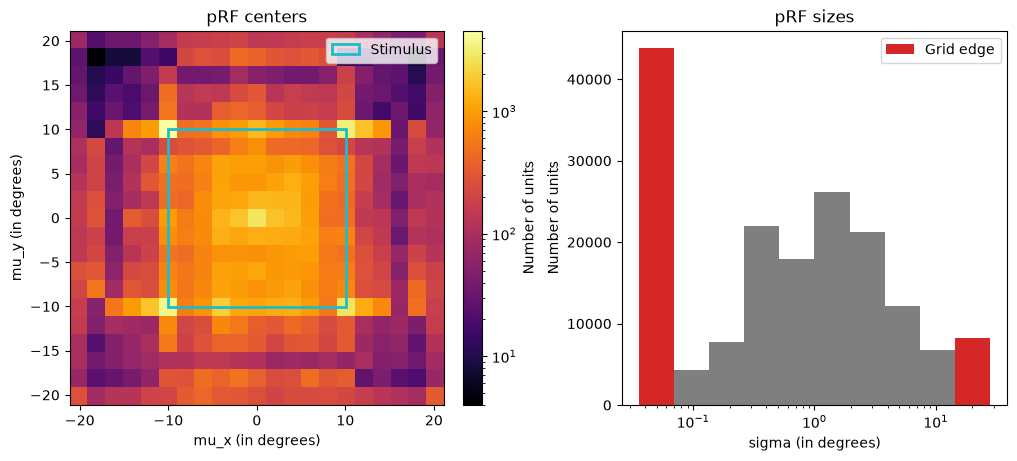

In [24]:
from prfmodel.plotting import plot_2d_prf_centers, plot_grid_parameter_distribution

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")

# Count estimates for each combination of pRF center coordinates in the grid
plot_2d_prf_centers(grid_params, grid_param_ranges, stimulus=stimulus, ax=axes[0])
axes[0].set(xlabel="mu_x (in degrees)", ylabel="mu_y (in degrees)", title="pRF centers")

# Count estimates for each pRF size in the grid
plot_grid_parameter_distribution(grid_params, grid_param_ranges, "sigma", ax=axes[1])  # Detects log spacing
axes[1].set(xlabel="sigma (in degrees)", title="pRF sizes");

In [26]:
from prfmodel.fitters import LeastSquaresFitter

# Create least-squares fitter
ls_fitter = LeastSquaresFitter(
    model=prf_model,
    stimulus=stimulus,
)

# Run least squares fit
ls_history, ls_params = ls_fitter.fit(
    data=data.T,
    parameters=grid_params,
    slope_name="amplitude",  # Names of parameters to be optimized with least squares
    intercept_name="baseline",
    batch_size=200,
)

Processing data batches:   0%|          | 0/853 [00:00<?, ?it/s]

In [29]:
import numpy as np
import pandas as pd
from keras import ops
from prfmodel.fitters import SGDFitter
from prfmodel.fitters.adapter import Adapter, ParameterTransform


def safe_log(x):
    if isinstance(x, (pd.Series, np.ndarray)):
        return np.log(x)
    return ops.log(x)


def safe_exp(x):
    if isinstance(x, (pd.Series, np.ndarray)):
        return np.exp(x)
    return ops.exp(x)


adapter = Adapter([ParameterTransform(["sigma"], transform_fun=safe_log, inverse_fun=safe_exp)])

import torch

torch._inductor.config.layout_optimization = False      # Saute l'étape qui plante
torch._dynamo.config.automatic_dynamic_shapes = False    # Évite la recompilation en "dynamic"

sgd_fitter = SGDFitter(
    model=prf_model,
    stimulus=stimulus,
    adapter=adapter,
    compile_step=True,  
)

sgd_history, sgd_params = sgd_fitter.fit(
    data=data.T,
    init_parameters=ls_params,
    fixed_parameters=["weight_deriv"],  # Fix weight_deriv to starting value
    batch_size=20_000,
    num_steps=100,
)

Processing data batches:   0%|          | 0/9 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/100 [00:00<?, ?it/s]

W1106 14:37:43.684000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [23/8] torch._dynamo hit config.recompile_limit (8)
W1106 14:37:43.684000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [23/8]    function: '_track_variables' (/Users/uriel/softwares/anaconda3/envs/prfmodel_env/lib/python3.12/site-packages/keras/src/backend/torch/layer.py:21)
W1106 14:37:43.684000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [23/8]    last reason: 23/7: ___check_obj_id(self._trainable_variables[0], 14559466976), type=<class 'keras.src.backend.Variable'>  # if id(v) not in seen_ids:  # keras/src/layers/layer.py:678 in variables
W1106 14:37:43.684000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [23/8] User stack trace:
W1106 14:37:43.684000 3007 site-packages/torch/_dynamo/convert_frame.py:2061] [23/8]   File "/Users/uriel/softwares/anaconda3/envs/prfmodel_env/lib/python3.12/site-packages/keras/src/backend/torch/layer.py", line 25, in _track_variables
W1106 14:37

In [30]:
from prfmodel.models.prf import Gaussian2DCSSPRFModel, init_css_from_gaussian

css_model = Gaussian2DCSSPRFModel(impulse_model=impulse_model)

# Start from the Gaussian estimates with n = 0.5
css_init_params = init_css_from_gaussian(gaussian_params)

_, css_init_params = LeastSquaresFitter(model=css_model, stimulus=stimulus_first).fit(
    data=response_first,
    parameters=css_init_params,
    slope_name="amplitude",
    intercept_name="baseline",
    batch_size=200,
)

css_sgd_fitter = SGDFitter(
    model=css_model,
    stimulus=stimulus_first,
    adapter=Adapter([ParameterTransform(["sigma", "n"], transform_fun=ops.log, inverse_fun=ops.exp)]),
    optimizer=Adam(learning_rate=learning_rate),
    compile_step=True,
)

css_history, css_params = css_sgd_fitter.fit(
    data=response_first,
    init_parameters=css_init_params,
    fixed_parameters=["weight_deriv"],
    num_steps=num_steps,
)

css_params

NameError: name 'gaussian_params' is not defined

# Brouillon

In [ ]:
# Define directories and files names (fn)
output_folder = analysis_info["output_folder"]
if input_fn.endswith('.nii'):
    prf_fit_dir = "{}/{}/derivatives/pp_data/{}/170k/{}/fit".format(
        main_dir, project_dir, subject, output_folder)
    os.makedirs(prf_fit_dir, exist_ok=True)

elif input_fn.endswith('.gii'):
    prf_fit_dir = "{}/{}/derivatives/pp_data/{}/fsnative/{}/fit".format(
        main_dir, project_dir, subject,  output_folder)
    os.makedirs(prf_fit_dir, exist_ok=True)

css_fit_fn = input_fn.split('/')[-1]
css_fit_fn = css_fit_fn.replace('bold', f'{analysis_name}-css{dm_name}_fit') 

css_pred_fn = input_fn.split('/')[-1] 
css_pred_fn = css_pred_fn.replace('bold', f'{analysis_name}-css{dm_name}_pred')

#------------LOAD DATA----------------
img, data = load_surface(fn=input_fn) #shape: (n times, n vertices)
# Exclude vertices with all-NaN timeseries to avoid errors during fitting
valid_vertices = ~np.isnan(data).any(axis=0)
valid_vertices_idx = np.where(valid_vertices)[0]
# Filter data to only include valid vertices
data_clean = data[:, valid_vertices]
n_excluded = data.shape[1] - data_clean.shape[1]
if n_excluded > 0:
    print(f"Excluded {n_excluded} vertices with all-NaN values")
print(f"Fitting {valid_vertices.sum()} valid vertices")


#----------GAUSSIAN GRID -----------------
rows, columns = dm.shape[0], dm.shape[1]                                               # design size (50 x 50)
design = np.moveaxis(dm, -1, 0)                                                        # time first, then rows, then columns

screen_deg = 2 * np.degrees(np.arctan(screen_size_cm[1] / (2 * screen_distance_cm)))   # screen height in dva
pixel_size = screen_deg / rows                                                         # each design pixel covers screen_deg / rows dva

x = (np.arange(columns) - (columns - 1) / 2) * pixel_size                              # pixel centres, left -> right
y = -(np.arange(rows) - (rows - 1) / 2) * pixel_size                                   # pixel centres, top -> bottom (row 0 = +y, as in prfpy)
xv, yv = np.meshgrid(x, y)
# y comes first because design axis 1 is the row (height) axis
grid_coordinates = np.stack((yv, xv), axis=-1)                                         # shape (rows, columns, 2)

# [PRFMODEL] prfmodel >= 0.1.0 (commit 7613361, 2026-10-26): frame_duration (duration of one design frame in s = TR)
# is now a required argument of PRFStimulus (see CHANGELOG.md of prfmodel); it equals the HRF resolution below
# AVANT : stimulus = PRFStimulus(design = design, grid = grid_coordinates)
stimulus = PRFStimulus(design = design, grid = grid_coordinates, frame_duration = tr)

# create 2D Gaussian prf model 
impulse_model = DerivativeTwoGammaImpulse(resolution=tr)
# Only weight_deriv is set; the two-gamma parameters use the model's default Glover HRF values
impulse_default_params = pd.DataFrame({
    "weight_deriv": [-0.5],
})

# Define pRF model with custom impulse response submodel
prf_model = Gaussian2DPRFModel(
    impulse_model=impulse_model,
)
# Same Gaussian + HRF, but centre given as (ecc, polar): used only for the grid search
polar_model = CanonicalPRFModel(prf_model=PolarGaussian2DPRFTuning(), impulse_model=impulse_model)

# Define model parameter grid range (as in prf_cssfit.py)
sizes  = max_ecc_size * np.linspace(0.1, 1, gauss_grid_nr)**2
eccs   = max_ecc_size * np.linspace(0.1, 1, gauss_grid_nr)**2
polars = np.linspace(0, 2 * np.pi, gauss_grid_nr)

grid_fitter = GridFitter(model=polar_model, stimulus=stimulus, compile_step=True)
_, grid_params = grid_fitter.fit(data=data_clean.T, batch_size=216, parameter_values={   # 216 divides 36^3 = 46656: no recompile on last batch
    "ecc": eccs, "polar": polars, "sigma": sizes,
    "weight_deriv": [-0.5], "baseline": [0.0], "amplitude": [1.0]})

grid_params = polar_to_cartesian(grid_params)                                         # (ecc, polar) -> (mu_x, mu_y) for least squares / SGD


# -----------LEAST SQUARES FIT ------------
# Amplitude and baseline for the grid result 
print("Running least squares fit....")
ls_fitter = LeastSquaresFitter(model=prf_model, stimulus=stimulus)
_, gaussian_params = ls_fitter.fit(data=data_clean.T, parameters=grid_params,        #override the gaussian parameters
                                   slope_name="amplitude", intercept_name="baseline", batch_size=None)


# ---------- ITERATIVE GAUSSIAN FIT --------------
gauss_sgd = SGDFitter(model=prf_model, stimulus=stimulus, compile_step=True,
                      adapter=Adapter([ParameterTransform(["sigma"], host_safe(ops.log), host_safe(ops.exp))]),
                      optimizer=keras.optimizers.Adam(learning_rate=0.01))
gauss_history, gaussian_params = gauss_sgd.fit(data=data_clean.T, init_parameters=gaussian_params,
                                               fixed_parameters=["weight_deriv"], num_steps=1000)


# -----------CSS FIT WITH SGD ----------------
css_adapter = Adapter([
    ParameterTransform(["sigma", "n"], host_safe(ops.log), host_safe(ops.exp))                             #adapter that log-transforms sigma and n during parameter optimization, forcing them to stay positive.
])

# 1. CSS model (compression here)
css_model = Gaussian2DPRFModel(
    encoding_model=CompressiveEncoder(encoding_model=PRFStimulusEncoder()),
    impulse_model=impulse_model,
)

# --- CSS grid over n (prfpy: exponent grid, size scaled by sqrt(n)) ---
corr_loss = CorrelationLoss(reduction="none")                                       # returns -r per vertex

n_grid = np.linspace(css_exponent_bounds[0], css_exponent_bounds[1], css_grid_nr)
best_r, best_n = np.full(len(data_clean.T), -np.inf), np.full(len(data_clean.T), n_grid[-1])
for n_val in n_grid:
    # [PRFMODEL] prfmodel 0.1.0 removed the 'gain' parameter of CompressiveEncoder (it traded off exactly against amplitude, see CHANGELOG.md)
    # AVANT : params_n = gaussian_params.assign(gain=1.0, n=n_val, sigma=gaussian_params["sigma"] * np.sqrt(n_val))
    params_n = gaussian_params.assign(n=n_val, sigma=gaussian_params["sigma"] * np.sqrt(n_val))
    pred_n = batched(css_model)(stimulus, params_n, batch_size=len(params_n))
    r = -ops.convert_to_numpy(corr_loss(data_clean.T, pred_n))  # Pearson r per vertex
    is_better = r > best_r
    best_r[is_better], best_n[is_better] = r[is_better], n_val

# [PRFMODEL] prfmodel 0.1.0 removed the 'gain' parameter of CompressiveEncoder (it traded off exactly against amplitude, see CHANGELOG.md)
# AVANT : init_params = gaussian_params.assign(gain=1.0, n=best_n, sigma=gaussian_params["sigma"] * np.sqrt(best_n))
init_params = gaussian_params.assign(n=best_n, sigma=gaussian_params["sigma"] * np.sqrt(best_n))
_, init_params = LeastSquaresFitter(model=css_model, stimulus=stimulus).fit(
    data=data_clean.T, parameters=init_params, slope_name="amplitude", intercept_name="baseline", batch_size=None)

# --- Iterative CSS fit ---
n_lo, n_hi = css_exponent_bounds                                                   # n_th = [0.01, 1]
css_adapter = Adapter([ParameterTransform(["sigma"], host_safe(ops.log), host_safe(ops.exp)),
                       bounded_transform(["n"], n_lo, n_hi)])
init_params = clip_to_bounds(init_params, {"n": (n_lo, n_hi)})                     # the n grid ends exactly at 1.0

css_sgd = SGDFitter(model=css_model, stimulus=stimulus, adapter=css_adapter, compile_step=True,
                    optimizer=keras.optimizers.Adam(learning_rate=0.01))
# [PRFMODEL] prfmodel 0.1.0 removed the 'gain' parameter of CompressiveEncoder (it traded off exactly against amplitude, see CHANGELOG.md)
# AVANT : fixed_parameters=["weight_deriv", "gain"]
css_history, css_params = css_sgd.fit(data=data_clean.T, init_parameters=init_params,
                                      fixed_parameters=["weight_deriv"], num_steps=1000)

print("All fitted!!")

# SGD convergence check: mean loss every 100 steps (should plateau before num_steps)
print("Gaussian SGD loss:", [round(float(v), 5) for v in gauss_history.history["loss"][::100]])
print("CSS SGD loss:     ", [round(float(v), 5) for v in css_history.history["loss"][::100]])

# ------------ PREDICTION FROM CSS AND SAVING ------------------
# 3. Prediction = same CSS model + SGD parameters -> compressed response
css_pred = batched(css_model)(stimulus, css_params, batch_size=len(css_params))               # the CSS model, NOT the Gaussian prf_model # np.ndarray, (n_valid_vertices, n_frames)


# Rearrange CSS results into the prf_cssfit.py layout (columns selected by name)
p = css_params
css_fit = np.column_stack([
    p["mu_x"], p["mu_y"], p["sigma"],
    # [PRFMODEL] prfmodel 0.1.0 removed the 'gain' parameter of CompressiveEncoder (it traded off exactly against amplitude, see CHANGELOG.md)
    # AVANT : p["amplitude"] * p["gain"],
    p["amplitude"],
    p["baseline"], p["n"],
    p["weight_deriv"],                                                             # hrf_1 slot: NOT on prfpy's scale (see below)
    np.zeros(len(p)),                                                              # hrf_2 slot: fixed at 0, as in your prfpy bounds
])

css_fit_mat = np.full((data.shape[1], css_params_num), np.nan, dtype=float)        # (n_vertices, 9)
css_pred_mat = np.full_like(data, np.nan, dtype=float)                             # (188, n_vertices)

css_fit_mat[valid_vertices, :8] = css_fit
css_pred_mat[:, valid_vertices] = css_pred.T
css_fit_mat[:, 8] = r2_score_surf(bold_signal=data, model_prediction=css_pred_mat)

if 'loo-avg' in input_fn:
    loo_bold_fn = input_fn.replace('loo-avg-', 'loo-')
    loo_img, loo_bold = load_surface(fn=loo_bold_fn)
    loo_r2 = r2_score_surf(bold_signal=loo_bold, model_prediction=css_pred_mat)
    css_fit_mat = np.column_stack((css_fit_mat, loo_r2))
    maps_names = ['mu_x', 'mu_y', 'prf_size', 'prf_amplitude', 'bold_baseline',
                  'n', 'hrf_1', 'hrf_2', 'r_squared', 'loo_r_squared']
else:
    maps_names = ['mu_x', 'mu_y', 'prf_size', 'prf_amplitude', 'bold_baseline',
                  'n', 'hrf_1', 'hrf_2', 'r_squared']

assert css_fit_mat.shape == (data.shape[1], len(maps_names))
assert css_pred_mat.shape == data.shape

img_css_fit_mat = make_surface_image(data=css_fit_mat.T, source_img=img, maps_names=maps_names)
nb.save(img_css_fit_mat, '{}/{}'.format(prf_fit_dir, css_fit_fn))
print(f"Saved fit to: {prf_fit_dir}/{css_fit_fn}")
img_css_pred_mat = make_surface_image(data=css_pred_mat, source_img=img)           # no .T
nb.save(img_css_pred_mat, '{}/{}'.format(prf_fit_dir, css_pred_fn))
print(f"Saved prediction to: {prf_fit_dir}/{css_pred_fn}")

# Peak GPU memory (to tune batch sizes)
if torch.cuda.is_available():
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB "
          f"/ {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# Print duration
end_time = datetime.datetime.now()
print("\nStart time:\t{start_time}\nEnd time:\t{end_time}\nDuration:\t{dur}".format(start_time=start_time, 
                                                                                    end_time=end_time, 
                                                                                    dur=end_time - start_time))